# Lab 11 - Labeling and Augmenting a Detection Dataset

Object detection begins with reliable labels. In this lab, you will label a small set of images, check the labels, prepare a complete detection dataset, and create safe training augmentations.

## Objectives

- Create pedestrian bounding-box labels in YOLO format.
- Inspect label quality against reference annotations.
- Prepare a fixed train, validation, and test split.
- Augment training images without changing validation or test data.

In [3]:
%pip -q install "albumentations==1.4.24"

Note: you may need to restart the kernel to use updated packages.


In [4]:
%load_ext autoreload
%autoreload 2

from pathlib import Path
import importlib
import sys

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import FileLink, display
from PIL import Image

lab_candidates = [
    Path.cwd(),
    Path.cwd() / 'Lab11',
    Path.cwd() / 'Labs' / 'Obj_detection' / 'Lab11',
    Path('/content/Obj_detection/Lab11'),
    Path('/content/Lab11'),
]
for lab_root in lab_candidates:
    if (lab_root / 'labeler.html').exists() and (lab_root / 'detection_dataset.py').exists():
        break
else:
    raise FileNotFoundError('Keep all Lab11 files in the same folder.')

if str(lab_root) not in sys.path:
    sys.path.insert(0, str(lab_root))

import detection_dataset as dd
importlib.reload(dd)

workspace = lab_root / 'work'
workspace.mkdir(exist_ok=True)

In [5]:
source_root = dd.download_pennfudan(workspace / 'source')
practice_archive = dd.make_labeling_practice_bundle(
    source_root, workspace / 'labeling_practice', image_count=3
)

## YOLO labels

Each image has a text file with the same base name. Every object occupies one line. This lab has one class, pedestrian, with class ID `0`.

```text
class_id  x_center  y_center  width  height
```

The four box values are normalized by the image width and height, so each lies between 0 and 1.

## 1. Get the images

The Penn-Fudan Pedestrian dataset provides images and instance masks. The masks let us check labels after you create them. The next cell downloads the source once and creates a three-image annotation bundle.

In [6]:
source_root = dd.download_pennfudan(workspace / 'source')
practice_archive = dd.make_labeling_practice_bundle(
    source_root, workspace / 'labeling_practice', image_count=3
)

if 'google.colab' in sys.modules:
    from google.colab import files
    files.download(str(practice_archive))
    files.download(str(lab_root / 'labeler.html'))
else:
    print('Annotation images:')
    display(FileLink(practice_archive))
    print('Local labeler:')
    display(FileLink(lab_root / 'labeler.html'))

Annotation images:


C:\Users\lenovo\Desktop\lab 11\work\labeling_practice\pennfudan_labeling_images.zip

Local labeler:


c:\Users\lenovo\Desktop\lab 11\labeler.html

## 2. Label three images

1. Download the image archive and `labeler.html` from the previous cell.
2. Open `labeler.html` in a browser, load one image, and draw a tight box around each visible pedestrian.
3. Download the matching YOLO label file for every image.
4. Upload or copy the three `.txt` files into `work/manual_labels/`.

Label people separately when they overlap. Include the visible part of a person at an image edge, without extending the box into an unseen region.

In [7]:
manual_labels_dir = workspace / 'manual_labels'
manual_labels_dir.mkdir(exist_ok=True)
print(manual_labels_dir)

c:\Users\lenovo\Desktop\lab 11\work\manual_labels


## 3. Check the labels

The check below compares each uploaded label file with the reference mask for the same image. It reports matched boxes, repeated boxes, extra boxes, and missed pedestrians.

In [8]:
practice_images = sorted((workspace / 'labeling_practice' / 'images').glob('*.png'))
for image_path in practice_images:
    label_path = manual_labels_dir / f'{image_path.stem}.txt'
    if not label_path.exists():
        print(f'{image_path.name}: label file not found')
        continue
    report = dd.annotation_quality_report(source_root, image_path.name, label_path, iou_threshold=0.5)
    print(
        f"{image_path.name}: matched={len(report['matches'])}, "
        f"repeated={len(report['duplicate_indices'])}, "
        f"extra={len(report['extra_indices'])}, missed={len(report['missed_indices'])}"
    )

FudanPed00001.png: matched=2, repeated=0, extra=0, missed=0
FudanPed00002.png: matched=1, repeated=0, extra=1, missed=0
FudanPed00003.png: matched=1, repeated=1, extra=1, missed=0


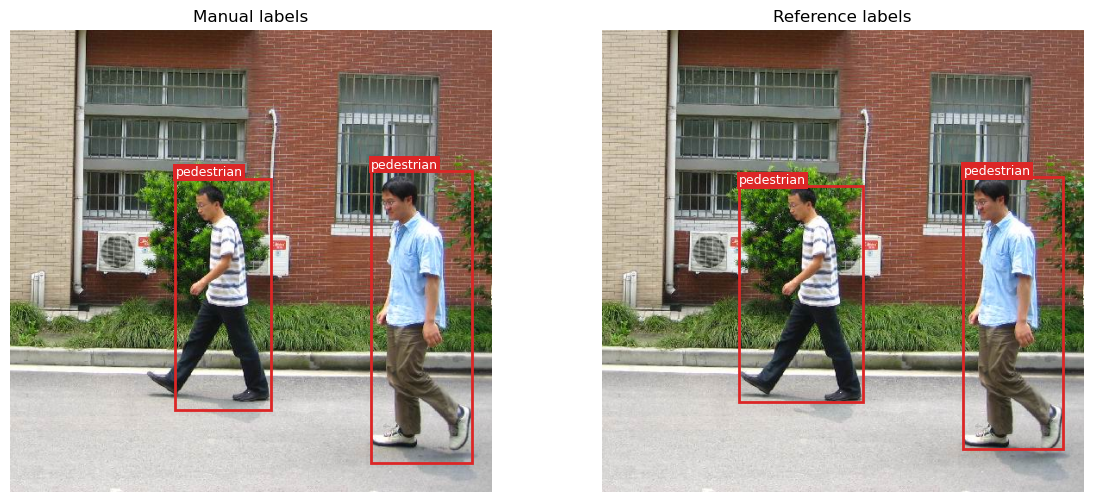

In [9]:
image_to_review = practice_images[0]
label_to_review = manual_labels_dir / f'{image_to_review.stem}.txt'

if label_to_review.exists():
    manual_class_ids, manual_boxes = dd.read_yolo_labels(label_to_review)
    reference_class_ids, reference_boxes = dd.reference_labels_for_image(source_root, image_to_review.name)
    with Image.open(image_to_review) as image:
        image_array = np.asarray(image.convert('RGB'))

    figure, axes = plt.subplots(1, 2, figsize=(14, 6))
    dd.plot_yolo_sample(axes[0], image_array, manual_class_ids, manual_boxes)
    axes[0].set_title('Manual labels')
    dd.plot_yolo_sample(axes[1], image_array, reference_class_ids, reference_boxes)
    axes[1].set_title('Reference labels')
    plt.show()
else:
    print(f'Save {label_to_review.name} in {manual_labels_dir} and run this cell again.')

## 4. Prepare the complete dataset

Your labels provide annotation and quality-check practice. The complete dataset uses verified mask-derived annotations so training starts from a reliable full set. It is split at image level before any augmentation, with a fixed seed so the next lab uses the same train, validation, and test images.

In [10]:
base_dataset_root = dd.prepare_base_dataset(
    source_root, workspace / 'pennfudan_yolo', seed=2026
)
base_summary = dd.validate_yolo_dataset(base_dataset_root)
print('Base dataset:', base_dataset_root)
for split, counts in base_summary.items():
    print(f"{split}: {counts['images']} images, {counts['boxes']} boxes")
print('Configuration:', base_dataset_root / 'data.yaml')

Base dataset: C:\Users\lenovo\Desktop\lab 11\work\pennfudan_yolo
train: 119 images, 291 boxes
val: 26 images, 68 boxes
test: 25 images, 64 boxes
Configuration: C:\Users\lenovo\Desktop\lab 11\work\pennfudan_yolo\data.yaml


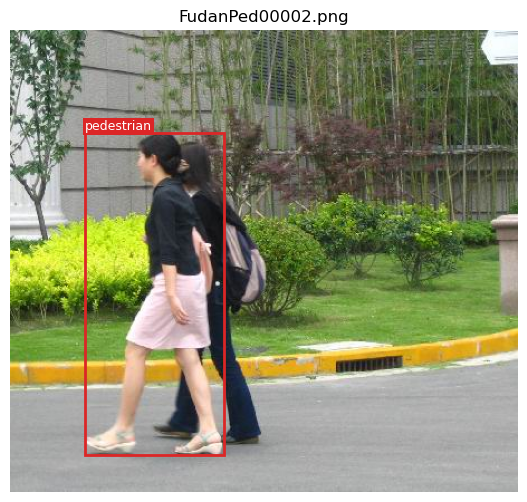

In [11]:
image_array, class_ids, boxes, image_path = dd.load_yolo_sample(base_dataset_root, 'train', index=0)
figure, axes = plt.subplots(figsize=(7, 6))
dd.plot_yolo_sample(axes, image_array, class_ids, boxes)
axes.set_title(image_path.name)
plt.show()

## 5. Augment training images

The augmentation creates one separate copy of every training image. It uses a horizontal flip and mild brightness or contrast variation. Validation and test images are copied unchanged.

In [12]:
augmented_dataset_root = dd.make_augmented_dataset(
    base_dataset_root,
    workspace / 'pennfudan_yolo_augmented',
    copies_per_image=1,
    seed=2026,
)
augmented_summary = dd.validate_yolo_dataset(augmented_dataset_root)
for split, counts in augmented_summary.items():
    print(f"{split}: {counts['images']} images, {counts['boxes']} boxes")

assert augmented_summary['val'] == base_summary['val']
assert augmented_summary['test'] == base_summary['test']
print('Validation and test splits are unchanged.')

train: 238 images, 582 boxes
val: 26 images, 68 boxes
test: 25 images, 64 boxes
Validation and test splits are unchanged.


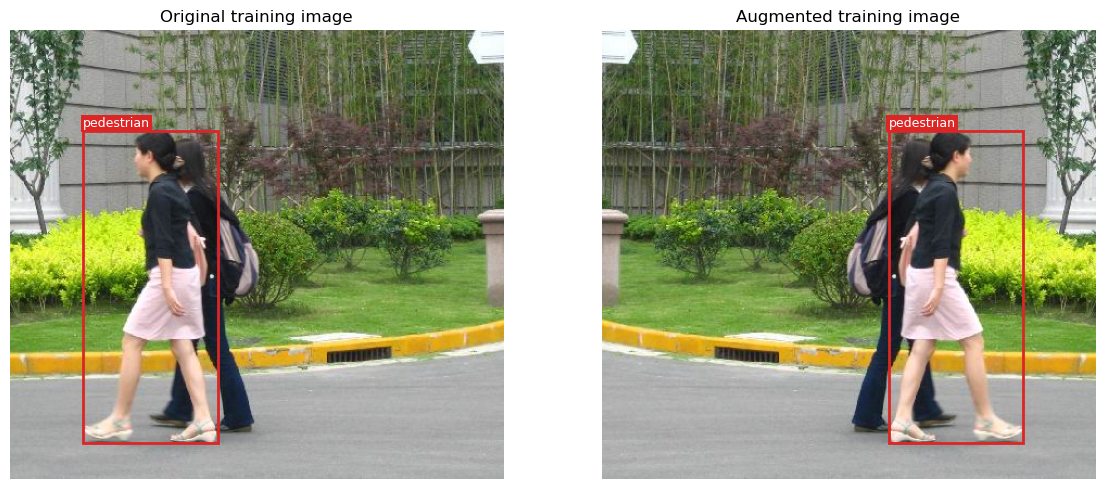

In [13]:
original_image, original_classes, original_boxes, original_path = dd.load_yolo_sample(
    base_dataset_root, 'train', index=0
)
augmented_path = augmented_dataset_root / 'train' / 'images' / f'{original_path.stem}_aug1.png'
augmented_classes, augmented_boxes = dd.read_yolo_labels(
    augmented_dataset_root / 'train' / 'labels' / f'{original_path.stem}_aug1.txt'
)
with Image.open(augmented_path) as image:
    augmented_image = np.asarray(image.convert('RGB'))

figure, axes = plt.subplots(1, 2, figsize=(14, 6))
dd.plot_yolo_sample(axes[0], original_image, original_classes, original_boxes)
axes[0].set_title('Original training image')
dd.plot_yolo_sample(axes[1], augmented_image, augmented_classes, augmented_boxes)
axes[1].set_title('Augmented training image')
plt.show()

## Check your understanding

1. Why are training images augmented after the split, rather than before it?<br>
If we training images augmented before split, the augmented picture will come in train set and validation set,is will result in Data leakage,let validation and test scores artificially high. 
\Split first and then only augment the training set. This way, you can make sure the validation and test sets are completely independent and don't include any artificially generated variants, so the evaluation results are real.


2. Why does a horizontal flip require an updated bounding box?<br>
Flipping horizontally will change the left and right direction of an image. A pedestrian who was originally on the left will end up on the right after the flip. If the coordinates of the bounding box aren't updated accordingly, the box will just hover over the original background. So, the horizontal center of the box needs to be recalculated (for example, the normalized center x becomes 1 - x) to keep the box snugged to the moved pedestrian.
3. Why would a vertical flip be a poor default choice for pedestrian images?<br>
Vertical flipping will turn pedestrians upside down. People rarely appear upside down in footage, which might hurt the model's performance in real-world scenarios.
4. What label problem could lead to a pedestrian being missed during training?
The most common labeling issue is missing annotations. If there are clearly pedestrians in an image but the corresponding .txt label file doesn’t have the box, the model will treat these pedestrians as background during training. Over time, the model will think similar areas have 'no people' during inference, leading to missed detections. Other problems, like boxes being too small or not snug to the objects, can also affect the model’s ability to locate things.